In [4]:
import numpy as np  
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv("~/Documents/DM/Progetto/dm1_26_27_dataset/seller_info_dm1_2627.csv")
df

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,...,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,...,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,...,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,...,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,...,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,...,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13838,59623.0,185,42625.0,0.0,28.0,12.0,2020.0,0.0,1.0,290.0,...,65,369,suv_crossover,gasoline,a,NaN,gray,franchise,mixed,high
13839,49530.0,155,31590.0,0.0,27.0,8.0,2020.0,0.0,1.0,305.0,...,64,370,suv_crossover,gasoline,a,fwd,white,franchise,mixed,medium
13840,49610.0,296,29992.5,0.0,48.0,9.0,2020.0,0.0,1.0,277.0,...,98,393,suv_crossover,gasoline,a,NaN,unknown,franchise,mixed,medium
13841,372531.0,235,32864.0,0.0,51.0,15.0,2020.0,0.0,1.0,285.0,...,71,435,suv_crossover,gasoline,a,NaN,black,franchise,mixed,medium


In [6]:
df['dominant_listing_color'].value_counts().reset_index() #non sembra qualcosa che possa avere importanza


,dominant_listing_color,count
0,white,5167
1,black,4475
2,unknown,1510
3,silver,992
4,gray,875
5,red,417
6,blue,372
7,brown,17
8,green,12
9,gold,5


In [7]:
df.value_counts(['front_legroom_median']).reset_index()


,front_legroom_median,count
0,41.30,1388
1,42.00,856
2,42.20,838
3,41.70,751
4,41.20,669
...,...,...
100,54.35,1
101,67.00,1
102,43.65,1
103,45.10,1


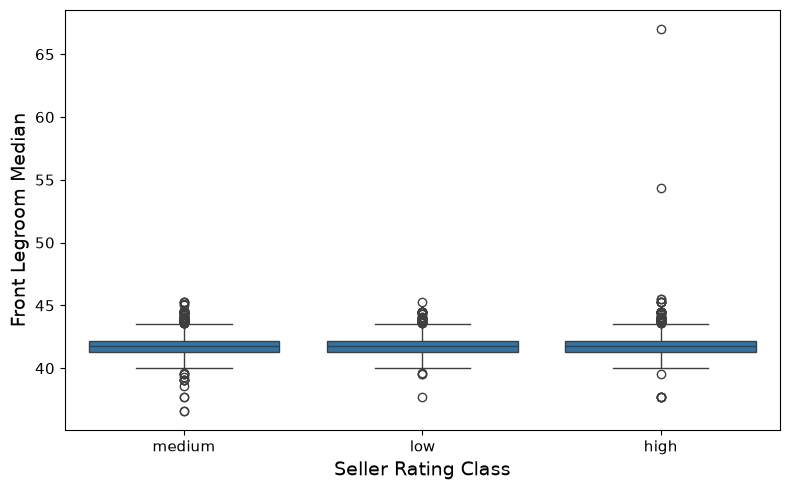

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="seller_rating_class", y="front_legroom_median")
plt.xlabel("Seller Rating Class", fontsize=14)
plt.ylabel("Front Legroom Median", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

In [9]:
df.value_counts(['back_legroom_median']).reset_index()

,back_legroom_median,count
0,38.30,699
1,39.00,673
2,37.40,612
3,38.60,610
4,38.00,533
...,...,...
247,41.60,1
248,34.15,1
249,43.10,1
250,33.25,1


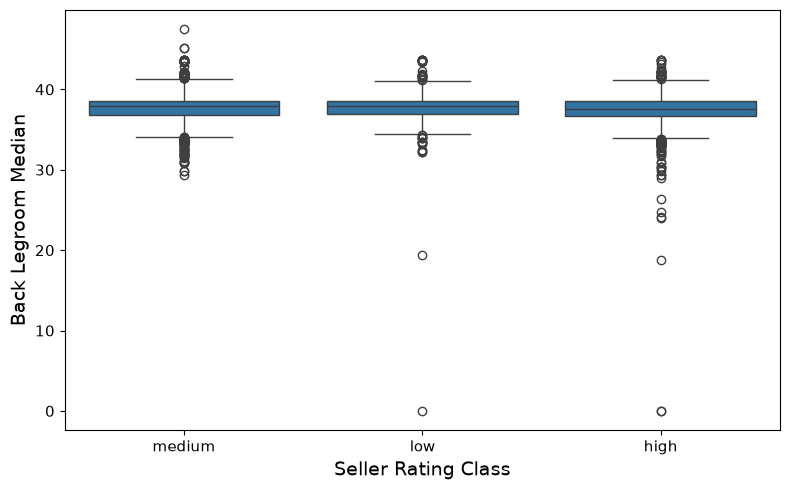

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="seller_rating_class", y="back_legroom_median")
plt.xlabel("Seller Rating Class", fontsize=14)
plt.ylabel("Back Legroom Median", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Count')

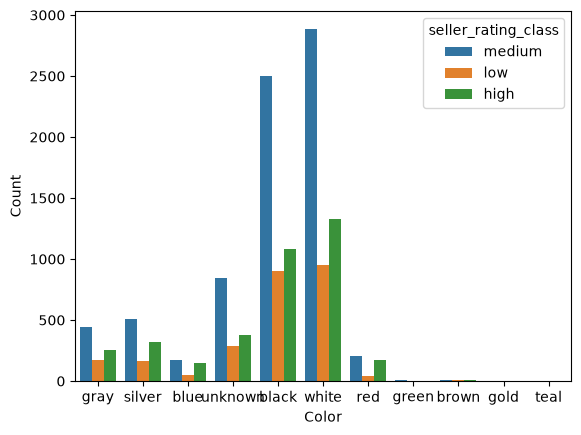

In [11]:
sns.countplot(data=df,x='dominant_listing_color',hue='seller_rating_class') #mi pare che si possa killare tranqullamente tutti i colori hanno la stessa distribuzione
plt.xlabel("Color")
plt.ylabel("Count")

<h4>Sturges</h4>

In [12]:
bins = np.log2(df['price_median'].count()) + 1
bins = int(bins.round())
bins

15

In [13]:
sumattr = df[['height_median','width_median','length_median']]*0.0254 #convertiamo in metri le dimensioni
sumattr

,height_median,width_median,length_median
0,1.75006,1.95834,4.96189
1,1.64338,1.84150,4.57962
2,1.47574,1.82880,4.78028
3,1.47066,1.83007,4.82727
4,1.78308,1.87960,4.76504
...,...,...,...
13838,1.66878,1.89992,4.86283
13839,1.70180,1.99644,5.03936
13840,1.76022,2.04470,4.91236
13841,1.76022,2.03200,4.90474


In [14]:
volume_median = sumattr.prod(axis=1).rename('volume_median')
df.insert(19, 'volume_median' , volume_median)


<h4>Arrotondo a massimo 1 decimale così che sia più elegante e che sia corrente con gli altri valori di mediana del dataset</h4>

In [15]:
decimals = 1 
df['volume_median'] = df['volume_median'].apply(lambda x: round(x, decimals))
df['volume_median']

0        17.0
1        13.9
2        12.9
3        13.0
4        16.0
         ... 
13838    15.4
13839    17.1
13840    17.7
13841    17.5
13842    14.9
Name: volume_median, Length: 13843, dtype: float64

<h4>Faccio dei boxplot per vedere la distribuzione del volume per ogni classe. Pressocchè hanno tutte la stessa distribuzione quindi non so quanto possa essere rilevante come attributo.</h4>

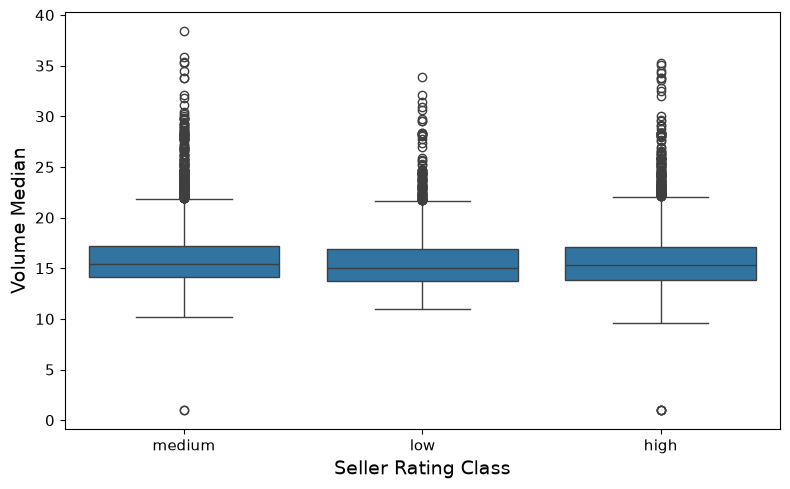

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="seller_rating_class", y="volume_median")
plt.xlabel("Seller Rating Class", fontsize=14)
plt.ylabel("Volume Median", fontsize=14)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
df.loc[:,'n_listings':'pct_theft_title'].corr(method="pearson").style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)
# vedo tutte le correlazioni che mi aspetto di trovare qui in realtà, ne possiamo contare tante, qualcuna che vogliamo analizzare in particolare?


,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,volume_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title
n_listings,1.000000,0.312576,-0.377757,-0.083279,-0.520089,0.478536,-0.476395,-0.419346,0.002778,-0.167436,0.204058,0.170459,0.259626,0.089600,-0.121011,0.109777,-0.007336,0.126210,0.088456,0.086346,0.597444,-0.084401,-0.065696
price_median,0.312576,1.000000,-0.141591,-0.023305,-0.682818,0.553119,-0.548488,-0.517285,0.555560,0.085814,-0.028478,-0.088448,0.269508,0.038488,0.182092,0.139893,0.163672,0.476408,0.281571,-0.064215,0.554128,-0.114542,-0.102632
savings_amount_median,-0.377757,-0.141591,1.000000,-0.003082,0.383409,-0.292395,0.283526,0.230372,0.145922,0.191173,-0.155634,-0.115305,-0.196337,-0.025017,0.157096,-0.121214,0.063535,-0.048971,-0.046491,0.007399,-0.661608,-0.065346,0.018274
daysonmarket_median,-0.083279,-0.023305,-0.003082,1.000000,0.076075,-0.127903,0.102713,0.140531,0.010031,0.048389,-0.068966,-0.067594,-0.082548,-0.030505,0.048737,-0.009464,0.012417,0.007507,0.004289,0.023360,-0.024862,0.038441,0.016154
mileage_median,-0.520089,-0.682818,0.383409,0.076075,1.000000,-0.825851,0.819994,0.779075,-0.138841,0.259526,-0.301111,-0.262709,-0.351092,-0.121094,0.168237,-0.102284,0.047040,-0.283547,-0.121630,-0.132895,-0.756845,0.092187,0.110250
year_median,0.478536,0.553119,-0.292395,-0.127903,-0.825851,1.000000,-0.996335,-0.782171,0.109443,-0.264110,0.320742,0.290962,0.435780,0.091473,-0.112682,0.224704,0.042696,0.307670,0.219368,0.207183,0.684365,-0.096292,-0.093658
vehicle_age_median,-0.476395,-0.548488,0.283526,0.102713,0.819994,-0.996335,1.000000,0.778783,-0.113097,0.258129,-0.318175,-0.288782,-0.437782,-0.095462,0.107538,-0.228232,-0.049746,-0.310708,-0.224525,-0.213344,-0.677677,0.092935,0.092537
owner_count_median,-0.419346,-0.517285,0.230372,0.140531,0.779075,-0.782171,0.778783,1.000000,-0.098759,0.205225,-0.276384,-0.237123,-0.350106,-0.098516,0.080622,-0.209668,-0.049778,-0.272104,-0.199201,-0.128343,-0.553433,0.142901,0.127743
horsepower_median,0.002778,0.555560,0.145922,0.010031,-0.138841,0.109443,-0.113097,-0.098759,1.000000,0.713535,-0.591612,-0.614380,0.282141,0.033552,0.725160,0.448295,0.639814,0.677332,0.656910,-0.095235,0.060016,-0.058604,-0.051318
engine_displacement_median,-0.167436,0.085814,0.191173,0.048389,0.259526,-0.264110,0.258129,0.205225,0.713535,1.000000,-0.678690,-0.672604,0.154717,-0.027403,0.826402,0.525970,0.727734,0.390404,0.624746,-0.089846,-0.201081,-0.010981,-0.010036


<Axes: >

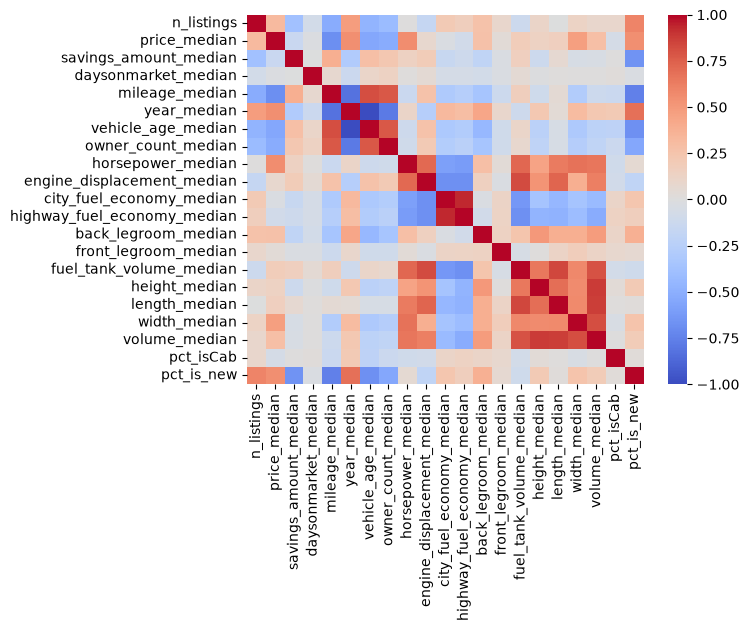

In [18]:
sns.heatmap(df.loc[:,'n_listings':'pct_is_new'].corr(method='pearson'),cmap="coolwarm", vmin=-1, vmax=1, annot=False, )

<h4>Qui tutti gli attributi che leverei per ora</h4>

In [19]:
killcolumns = ['dominant_body_type','pct_isCab','dominant_transmission','dominant_fuel_type','pct_salvage','dominant_wheel_system','dominant_listing_color','height_median','length_median','width_median','back_legroom_median','front_legroom_median']
df = df.drop(killcolumns,axis=1)
df

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,...,highway_fuel_economy_median,fuel_tank_volume_median,volume_median,pct_is_new,pct_theft_title,n_listing_days,listing_span_days,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,...,23.5,21.00,17.0,0.000000,0.000000,15,156,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,...,28.5,15.90,13.9,0.000000,0.000000,14,589,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,...,28.5,17.50,12.9,0.000000,0.000000,15,97,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,...,35.0,16.50,13.0,0.000000,0.000000,7,338,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,...,22.0,21.10,16.0,0.000000,0.071429,6,315,independent,used_only,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13838,59623.0,185,42625.0,0.0,28.0,12.0,2020.0,0.0,1.0,290.0,...,27.0,17.20,15.4,0.735135,0.000000,65,369,franchise,mixed,high
13839,49530.0,155,31590.0,0.0,27.0,8.0,2020.0,0.0,1.0,305.0,...,29.0,19.00,17.1,0.787097,0.000000,64,370,franchise,mixed,medium
13840,49610.0,296,29992.5,0.0,48.0,9.0,2020.0,0.0,1.0,277.0,...,26.0,19.00,17.7,0.625000,0.009009,98,393,franchise,mixed,medium
13841,372531.0,235,32864.0,0.0,51.0,15.0,2020.0,0.0,1.0,285.0,...,26.0,21.10,17.5,0.685106,0.013333,71,435,franchise,mixed,medium
